# 06 · An MLP for regression, end to end

This is the first complete "train a network" task — the shape of homework sub-tasks D, E and F: iterators → model class → training loop with validation → curves → test loss → example predictions. Everything from notebooks 01–05 comes together.

---
## Theory in 60 seconds

- **MLP**: `Linear → activation → Linear → activation → … → Linear`. Hidden layers with a non-linearity (ReLU: `max(0, z)`) let the network represent curved relationships and interactions between features.
- **Output layer for regression**: one neuron per predicted quantity, **no activation** (the output must be free to take any real value). Loss: **MSE**.
- **Three data splits, three jobs**: *training* set → gradient updates; *validation* set → decisions made by you (number of epochs, learning rate, architecture); *test* set → one final, honest number.
- `model.train()` / `model.eval()` only set a flag (it matters for layers such as dropout); `torch.no_grad()` switches off graph recording. For evaluation use both.
- Reading curves: both losses high and flat → under-fitting (or learning rate too low); training loss falling while validation loss rises → over-fitting.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from dnd_utils import check, load_houses

d = load_houses()
X_train, y_train = d["X_train"], d["y_train"]          # (720, 13) and (720,)  NumPy float32; y = price in k€
X_val, y_val = d["X_val"], d["y_val"]
X_test, y_test = d["X_test"], d["y_test"]
print(X_train.shape, y_train.shape, "| mean price", y_train.mean().round(1), "std", y_train.std().round(1))

(720, 13) (720,) | mean price 205.3 std 89.5


---
## Exercise 6.1 · Data loaders (repetition from 05 — from memory!)

`Dataset` subclass + three loaders, batch size 32. Batches: `(batch, 13)` and `(batch, 1)`, `float32`.

In [2]:
class RegressionDataset(Dataset):
    def __init__(self, x, y):
        self.xs = torch.tensor(x, dtype=torch.float32)
        self.ys = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return self.xs.shape[0]

    def __getitem__(self, idx):
        return self.xs[idx], self.ys[idx, None]

loader_train = DataLoader(RegressionDataset(X_train, y_train), batch_size=32, shuffle=True)
loader_val = DataLoader(RegressionDataset(X_val, y_val), batch_size=32, shuffle=True)
loader_test = DataLoader(RegressionDataset(X_test, y_test), batch_size=32, shuffle=False)

In [3]:
check("train batch: (32, 13) and (32, 1), float32", lambda: (lambda b: b[0].shape == (32, 13) and b[1].shape == (32, 1) and b[1].dtype == torch.float32)(next(iter(loader_train))))
check("test loader keeps the order", lambda: torch.equal(torch.cat([y for _, y in loader_test])[:, 0], torch.tensor(y_test)))

✅ train batch: (32, 13) and (32, 1), float32
✅ test loader keeps the order


True

---
## Exercise 6.2 · The model class, two ways

Architecture: `13 → 32 → 16 → 1`, ReLU after the two hidden layers.

**a)** Before writing code: how many trainable parameters?

In [4]:
n_params_by_hand = (13 * 32 + 32) + (32 * 16 + 16) + (16 * 1 + 1)       # 448 + 528 + 17 = 993

**b)** Write `RegMLPExplicit`: three `nn.Linear` attributes created in `__init__`, and a `forward` that applies them step by step with `torch.relu` (or `nn.functional.relu`).

**c)** Write `RegMLP`: the same network with an `nn.Sequential`.

Both take `n_inputs` as constructor argument.

In [5]:
class RegMLPExplicit(nn.Module):
    def __init__(self, n_inputs):
        super().__init__()                         # must come first: sets up parameter registration
        self.linear1 = nn.Linear(n_inputs, 32)     # layers are created ONCE here (they own the weights) ...
        self.linear2 = nn.Linear(32, 16)
        self.linear3 = nn.Linear(16, 1)

    def forward(self, x):                          # ... and USED here, every time the model is called
        h = torch.relu(self.linear1(x))            # (batch, 13) -> (batch, 32)
        h = torch.relu(self.linear2(h))            # -> (batch, 16)
        return self.linear3(h)                     # -> (batch, 1), no activation: regression


class RegMLP(nn.Module):
    def __init__(self, n_inputs):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, 32), nn.ReLU(),
            nn.Linear(32, 16), nn.ReLU(),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.layers(x)

In [6]:
_xb = torch.randn(5, 13)
for cls_name in ("RegMLPExplicit", "RegMLP"):
    check(f"{cls_name}: output shape (5, 1)", lambda: globals()[cls_name](13)(_xb).shape == (5, 1))
    check(f"{cls_name}: 993 parameters", lambda: sum(p.numel() for p in globals()[cls_name](13).parameters()) == 993 == n_params_by_hand)
    check(f"{cls_name}: output can be negative (no activation at the end)", lambda: (lambda m: (m(torch.randn(500, 13)) < 0).any().item() and (m(torch.randn(500, 13)) > 0).any().item())((torch.manual_seed(4), globals()[cls_name](13))[1]))

✅ RegMLPExplicit: output shape (5, 1)
✅ RegMLPExplicit: 993 parameters
✅ RegMLPExplicit: output can be negative (no activation at the end)
✅ RegMLP: output shape (5, 1)
✅ RegMLP: 993 parameters
✅ RegMLP: output can be negative (no activation at the end)


What happens if you forget `super().__init__()`? And what if you create a layer inside `forward` instead of `__init__` (e.g. `return nn.Linear(16, 1)(h)`)?

**Answer.** Without `super().__init__()` the first `self.something = nn.Linear(...)` raises `AttributeError: cannot assign module before Module.__init__() call` — the machinery that registers sub-modules and parameters does not exist yet. A layer created inside `forward` gets **new random weights on every call** and is not registered in `model.parameters()`, so the optimizer never updates it: the code runs without an error, but that layer never learns and the output is partly random noise.

---
## Exercise 6.3 · Why the non-linearity is essential

Claim: without an activation in between, two linear layers are exactly **one** linear layer.

Given `lin1` (13 → 8) and `lin2` (8 → 1), compute the weight matrix `W_eq` (shape `(1, 13)`) and bias `b_eq` (shape `(1,)`) of the single equivalent layer. Derive it on paper: substitute `h = W₁x + b₁` into `W₂h + b₂`.

In [7]:
torch.manual_seed(0)
lin1, lin2 = nn.Linear(13, 8), nn.Linear(8, 1)
xb = torch.randn(6, 13)

# W2 (W1 x + b1) + b2  =  (W2 W1) x + (W2 b1 + b2)
W_eq = lin2.weight @ lin1.weight                    # (1, 8) @ (8, 13) -> (1, 13)
b_eq = lin2.weight @ lin1.bias + lin2.bias          # (1, 8) @ (8,) -> (1,)

In [8]:
check("shapes", lambda: W_eq.shape == (1, 13) and b_eq.shape == (1,))
check("lin2(lin1(x)) == x @ W_eq.T + b_eq", lambda: torch.allclose(lin2(lin1(xb)), xb @ W_eq.T + b_eq, atol=1e-5))
check("with a ReLU in between it is NOT the same function", lambda: not torch.allclose(lin2(torch.relu(lin1(xb))), xb @ W_eq.T + b_eq, atol=1e-3))

✅ shapes
✅ lin2(lin1(x)) == x @ W_eq.T + b_eq
✅ with a ReLU in between it is NOT the same function


True

So a "deep" network without activations has exactly the expressive power of linear regression, however many layers it has. The ReLU between the layers is what buys the extra power.

---
## Exercise 6.4 · One epoch of training, one pass of evaluation

Write the two building blocks:

- `train_one_epoch(model, loader, loss_fn, optimizer)` — puts the model in training mode, performs one update per batch, returns the **mean of the batch losses** (a Python float).
- `evaluate(model, loader, loss_fn)` — evaluation mode, no gradients, no updates; returns the mean of the batch losses.

In [9]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    batch_losses = []
    for xb, yb in loader:
        pred = model(xb)                 # forward
        loss = loss_fn(pred, yb)         # scalar
        optimizer.zero_grad()            # clear old gradients
        loss.backward()                  # compute new ones
        optimizer.step()                 # update
        batch_losses.append(loss.item())
    return float(np.mean(batch_losses))

def evaluate(model, loader, loss_fn):
    model.eval()
    batch_losses = []
    with torch.no_grad():
        for xb, yb in loader:
            batch_losses.append(loss_fn(model(xb), yb).item())
    return float(np.mean(batch_losses))

In [10]:
torch.manual_seed(0)
_m = None
try: _m = RegMLP(13)
except Exception: pass
_before = [p.clone() for p in _m.parameters()] if _m is not None else None
check("evaluate returns a float and does not change the weights", lambda: isinstance(evaluate(_m, loader_val, nn.MSELoss()), float) and all(torch.equal(a, b) for a, b in zip(_before, _m.parameters())))
check("evaluate leaves no gradients behind", lambda: all(p.grad is None for p in _m.parameters()))
check("train_one_epoch returns a float and changes the weights", lambda: isinstance(train_one_epoch(_m, loader_train, nn.MSELoss(), torch.optim.Adam(_m.parameters(), lr=0.01)), float) and not all(torch.equal(a, b) for a, b in zip(_before, _m.parameters())))
check("model is in the right mode afterwards", lambda: (evaluate(_m, loader_val, nn.MSELoss()), _m.training)[1] is False)

✅ evaluate returns a float and does not change the weights
✅ evaluate leaves no gradients behind


✅ train_one_epoch returns a float and changes the weights
✅ model is in the right mode afterwards


True

---
## Exercise 6.5 · The training run

Train a **fresh** `RegMLP` for 80 epochs with `nn.MSELoss` and `Adam(lr=0.01)`. After every epoch store the training loss and the validation loss in `train_losses` / `val_losses`.

Start the cell with `torch.manual_seed(0)` **and create the model inside this cell** (see the question below).

In [11]:
torch.manual_seed(0)
model = RegMLP(X_train.shape[1])                     # a fresh model every time this cell runs
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

N_EPOCHS = 80
train_losses, val_losses = [], []
for epoch in range(N_EPOCHS):
    train_losses.append(train_one_epoch(model, loader_train, loss_fn, optimizer))
    val_losses.append(evaluate(model, loader_val, loss_fn))
    if epoch % 10 == 0 or epoch == N_EPOCHS - 1:
        print(f"epoch {epoch:3d}   train {train_losses[-1]:9.1f}   val {val_losses[-1]:9.1f}")

epoch   0   train   48955.2   val   39601.5


epoch  10   train     357.7   val     438.4


epoch  20   train     307.1   val     348.8


epoch  30   train     280.0   val     331.0


epoch  40   train     255.7   val     275.9


epoch  50   train     242.2   val     247.5
epoch  60   train     225.0   val     226.8


epoch  70   train     211.2   val     211.8
epoch  79   train     202.2   val     225.8


In [12]:
check("80 values in each list", lambda: len(train_losses) == len(val_losses) == 80)
check("the first epoch starts very high (tens of thousands)", lambda: train_losses[0] > 10000)
check("training loss ends below 400", lambda: train_losses[-1] < 400)
check("validation loss ends below 450", lambda: val_losses[-1] < 450)

✅ 80 values in each list
✅ the first epoch starts very high (tens of thousands)
✅ training loss ends below 400
✅ validation loss ends below 450


True

Why must the model (and the optimizer) be created **inside** the training cell? What would you see if you ran a training cell twice with the model created in an earlier cell?

**Answer.** The weights are randomly initialised when the model object is created, and training modifies that object in place. If the training cell only *uses* an existing model, a second run **continues** from the already-trained weights: the curves start low and look flat ("the loss is not improving"), and the number of epochs you believe you trained is wrong. This is the homework FAQ item *"the loss value looks good, but the plot shows that the loss is not improving"*. The optimizer belongs in the same cell: it holds references to the model's parameters and (Adam) its own running statistics.

---
## Exercise 6.6 · Plot the curves

One figure, both curves, axis labels, **a legend**. The first epochs are so high that the interesting part is squashed — set the y-limits so that the difference between the two curves near the end is clearly visible.

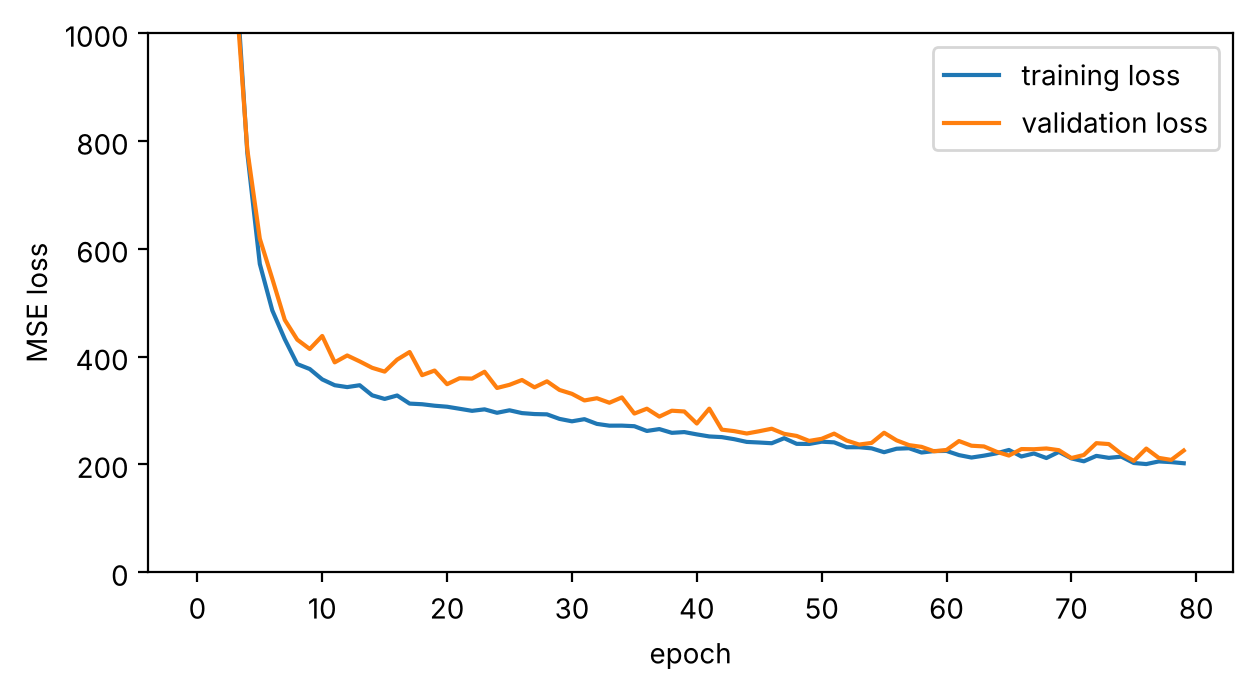

In [13]:
plt.figure(figsize=(7, 3.5))
plt.plot(train_losses, label="training loss")
plt.plot(val_losses, label="validation loss")
plt.xlabel("epoch")
plt.ylabel("MSE loss")
plt.ylim(0, 1000)                  # zoom in: the first epochs are in the tens of thousands
plt.legend()
plt.show()

Why is the loss of the very first epoch around 40 000? (Hint: what does an untrained network output, and what is the mean price?)

**Answer.** An untrained network outputs values near 0. The prices are around 200 k€ with a standard deviation of ~90, so the initial squared error is about `mean(y²) = mean² + variance ≈ 200² + 90² ≈ 48 000`. The first job of the network is simply to move its output level up to ~200 — which is why the curve drops steeply at first. (This is also why standardising the *target* can speed up regression training; you will do that in notebook 10.)

---
## Exercise 6.7 · The test set: one honest number, and context for it

- `test_mse`: the MSE on the **full** test set. Collect the predictions and labels of all batches, concatenate, compute the loss once.
- `baseline_mse`: the MSE on the test set of always predicting the **training** mean price.
- Also keep `preds` and `trues`, tensors of shape `(240, 1)`.

In [14]:
model.eval()
pred_batches, true_batches = [], []
with torch.no_grad():
    for xb, yb in loader_test:
        pred_batches.append(model(xb))
        true_batches.append(yb)
preds = torch.cat(pred_batches, dim=0)               # (240, 1)
trues = torch.cat(true_batches, dim=0)               # (240, 1)
test_mse = loss_fn(preds, trues).item()

baseline_mse = float(((y_test - y_train.mean()) ** 2).mean())
print(f"test MSE {test_mse:.1f}  (RMSE {test_mse ** 0.5:.1f} k€)   baseline {baseline_mse:.1f}  (RMSE {baseline_mse ** 0.5:.1f} k€)")

test MSE 220.0  (RMSE 14.8 k€)   baseline 7131.6  (RMSE 84.4 k€)


In [15]:
check("preds and trues have shape (240, 1)", lambda: preds.shape == trues.shape == (240, 1))
check("trues are the test labels in order", lambda: torch.equal(trues[:, 0], torch.tensor(y_test)))
check("baseline_mse", lambda: abs(baseline_mse - float(((y_test - y_train.mean()) ** 2).mean())) < 1)
check("test_mse is consistent with preds", lambda: abs(test_mse - ((preds - trues) ** 2).mean().item()) < 1e-2)
check("the network beats the baseline by a wide margin (test MSE < 300)", lambda: test_mse < 300)

✅ preds and trues have shape (240, 1)
✅ trues are the test labels in order
✅ baseline_mse
✅ test_mse is consistent with preds
✅ the network beats the baseline by a wide margin (test MSE < 300)


True

For reference: a plain **linear regression** on the same 13 inputs reaches a test MSE of about 335, and the noise built into the data has variance 144 — no model can do better than that. Where does your network sit between the two?

Now print the predicted and the true price of the first 8 test houses, one per line.

In [16]:
for p, t in zip(preds[:8, 0], trues[:8, 0]):
    print(f"predicted {p.item():7.1f} k€    true {t.item():7.1f} k€    error {p.item() - t.item():+6.1f}")

predicted   209.1 k€    true   199.9 k€    error   +9.2
predicted   302.8 k€    true   326.4 k€    error  -23.6
predicted   147.9 k€    true   127.0 k€    error  +20.9
predicted   127.5 k€    true   105.8 k€    error  +21.7
predicted   159.8 k€    true   152.7 k€    error   +7.1
predicted   273.4 k€    true   270.2 k€    error   +3.2
predicted   216.2 k€    true   219.5 k€    error   -3.3
predicted   265.6 k€    true   290.8 k€    error  -25.2


---
## Exercise 6.8 · Experiment: the learning rate

Write `run(lr, n_epochs=80, seed=0)` that trains a fresh `RegMLP` with `Adam(lr=lr)` and returns `(train_losses, val_losses)`. Then run it for `lr = 0.0001`, `0.001`, `0.01` and `0.1`, and plot the four validation curves in one figure (log y-axis: `plt.yscale("log")`).

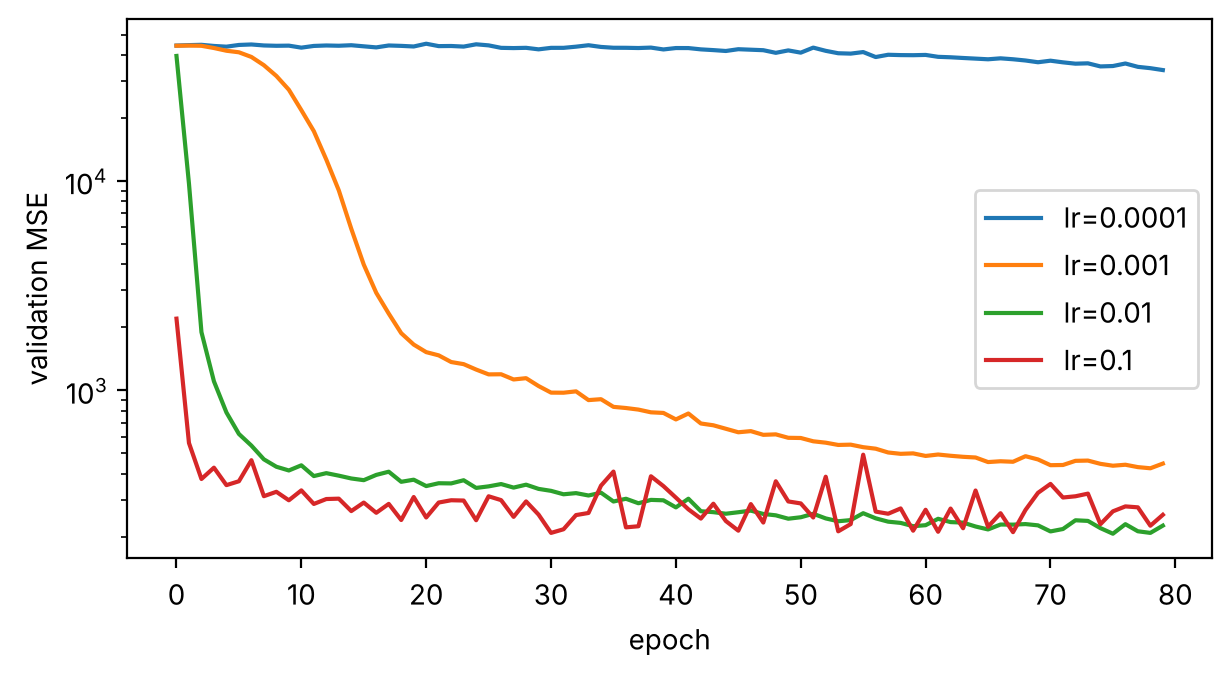

lr=0.0001   final train   38974.7   final val   33906.1
lr=0.001    final train     355.9   final val     446.7
lr=0.01     final train     202.2   final val     225.8
lr=0.1      final train     221.4   final val     254.3


In [17]:
def run(lr, n_epochs=80, seed=0):
    torch.manual_seed(seed)
    m = RegMLP(X_train.shape[1])
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    lf = nn.MSELoss()
    tr, va = [], []
    for _ in range(n_epochs):
        tr.append(train_one_epoch(m, loader_train, lf, opt))
        va.append(evaluate(m, loader_val, lf))
    return tr, va

results = {lr: run(lr) for lr in (0.0001, 0.001, 0.01, 0.1)}
plt.figure(figsize=(7, 3.5))
for lr, (tr, va) in results.items():
    plt.plot(va, label=f"lr={lr}")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("validation MSE"); plt.legend(); plt.show()
for lr, (tr, va) in results.items():
    print(f"lr={lr:<7}  final train {tr[-1]:9.1f}   final val {va[-1]:9.1f}")

In [18]:
check("four runs", lambda: sorted(results) == [0.0001, 0.001, 0.01, 0.1])
check("lr=0.0001 is still far from trained after 80 epochs", lambda: results[0.0001][1][-1] > 5 * results[0.01][1][-1])
check("lr=0.01 beats lr=0.001 after 80 epochs", lambda: results[0.01][1][-1] < results[0.001][1][-1])

✅ four runs
✅ lr=0.0001 is still far from trained after 80 epochs
✅ lr=0.01 beats lr=0.001 after 80 epochs


True

With `lr = 0.0001` both final losses are still enormous. A classmate says "the model is under-fitting, we need a bigger network". What is the better diagnosis, and which feature of the curve tells you?

**Answer.** The curve is **still going down steadily** at the last epoch — the model has not finished training, it is not incapable. The same architecture reaches a loss ~100× lower with a larger learning rate (or many more epochs). True under-fitting from lack of capacity shows a curve that has *flattened* at a high value although the learning rate is reasonable. Rule: before blaming the architecture, check that the curve has converged, and try a learning rate 10× larger and 10× smaller.

---
## Exercise 6.9 · Reproduce the famous bug

In notebook 01 you predicted what happens when the labels have shape `(batch,)` while the model outputs `(batch, 1)`. Now watch it happen. The dataset below returns **scalar** labels. Train a fresh `RegMLP` on `loader_bug` for 40 epochs (`Adam`, `lr=0.01`) with your `train_one_epoch`, then compute:

- `bug_final_loss`: the last training loss,
- `bug_pred_std`: the standard deviation of the model's predictions on the test inputs.

PyTorch prints a `UserWarning` about the sizes — in the test, **read warnings**; this one is the only signal you get.

In [19]:
class BuggyDataset(Dataset):
    def __init__(self, x, y):
        self.xs, self.ys = torch.tensor(x), torch.tensor(y)
    def __len__(self):
        return self.xs.shape[0]
    def __getitem__(self, idx):
        return self.xs[idx], self.ys[idx]             # <- scalar label: batches have shape (batch,)

loader_bug = DataLoader(BuggyDataset(X_train, y_train), batch_size=32, shuffle=True)

In [20]:
torch.manual_seed(0)
bug_model = RegMLP(13)
bug_opt = torch.optim.Adam(bug_model.parameters(), lr=0.01)
for epoch in range(40):
    bug_final_loss = train_one_epoch(bug_model, loader_bug, nn.MSELoss(), bug_opt)
bug_model.eval()
with torch.no_grad():
    bug_pred = bug_model(torch.tensor(X_test))
bug_pred_std = bug_pred.std().item()
print(f"final loss {bug_final_loss:.0f}   (variance of the training prices: {y_train.var():.0f})")
print(f"std of predictions {bug_pred_std:.1f}   (std of the true prices: {y_test.std():.1f})   mean prediction {bug_pred.mean().item():.1f}")

/usr/local/lib/python3.13/site-packages/torch/nn/modules/loss.py:630: UserWarning: Using a target size (torch.Size([32])) that is different to the input size (torch.Size([32, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
/usr/local/lib/python3.13/site-packages/torch/nn/modules/loss.py:630: UserWarning: Using a target size (torch.Size([16])) that is different to the input size (torch.Size([16, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


final loss 8095   (variance of the training prices: 8019)
std of predictions 3.8   (std of the true prices: 84.4)   mean prediction 220.3


In [21]:
check("the loss is stuck near the variance of the prices", lambda: 0.7 * y_train.var() < bug_final_loss < 1.3 * y_train.var())
check("the predictions are almost constant", lambda: bug_pred_std < 0.2 * y_test.std())

✅ the loss is stuck near the variance of the prices
✅ the predictions are almost constant


True

Commit the fingerprint to memory: **loss stuck at about the variance of the target + nearly identical predictions for all inputs = label shape bug** (or labels shuffled independently of inputs — same fingerprint).

---
## Blank-page drill (the big one)

Open a **new, empty notebook**. Without looking at anything, and with the clock running (target: under 25 minutes), write the complete regression task:

1. `from dnd_utils import load_houses` and get the six arrays (this is the only thing you may copy);
2. `Dataset` class and three `DataLoader`s;
3. an MLP class `13 → 25 → 25 → 1` with ReLU;
4. a training loop with training **and** validation loss per epoch (write the loop inline this time, not with helper functions);
5. the loss plot with legend;
6. the test MSE on the full test set, and 5 example predictions next to the true values.

Then compare with the solution of this notebook and note down **every line you had to think about** — those are your personal weak spots for the next repetition.

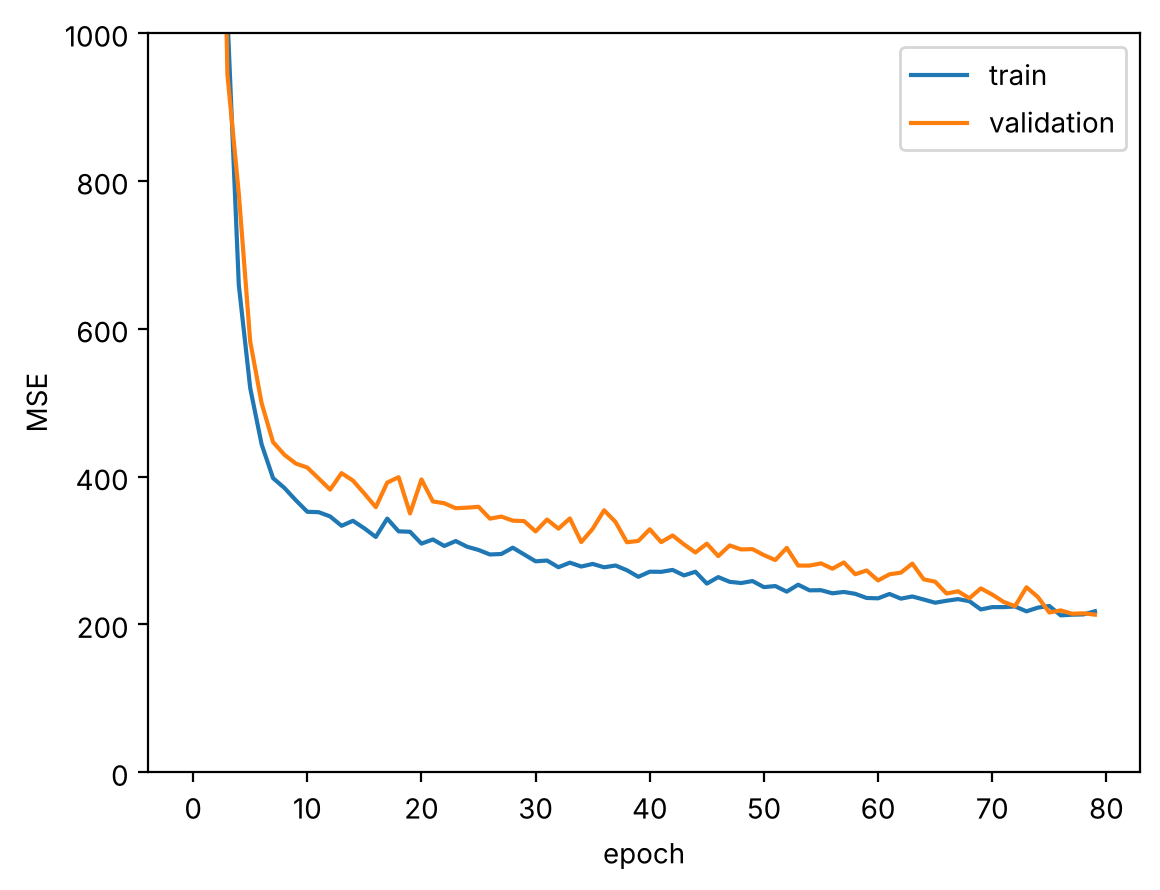

test MSE 208.92893981933594
  212.8    199.9
  303.8    326.4
  151.8    127.0
  120.8    105.8
  154.7    152.7


In [22]:
# A complete inline version, for comparison after your attempt.
class DS(Dataset):
    def __init__(self, x, y):
        self.xs = torch.tensor(x, dtype=torch.float32)
        self.ys = torch.tensor(y, dtype=torch.float32)
    def __len__(self):
        return self.xs.shape[0]
    def __getitem__(self, idx):
        return self.xs[idx], self.ys[idx, None]

dl_tr = DataLoader(DS(X_train, y_train), batch_size=32, shuffle=True)
dl_va = DataLoader(DS(X_val, y_val), batch_size=32, shuffle=True)
dl_te = DataLoader(DS(X_test, y_test), batch_size=32, shuffle=False)

class Net(nn.Module):
    def __init__(self, n_inputs):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(n_inputs, 25), nn.ReLU(), nn.Linear(25, 25), nn.ReLU(), nn.Linear(25, 1))
    def forward(self, x):
        return self.layers(x)

torch.manual_seed(0)
net = Net(X_train.shape[1])
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(net.parameters(), lr=0.01)
tr_hist, va_hist = [], []
for epoch in range(80):
    net.train()
    losses = []
    for xb, yb in dl_tr:
        loss = loss_fn(net(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    tr_hist.append(np.mean(losses))

    net.eval()
    losses = []
    with torch.no_grad():
        for xb, yb in dl_va:
            losses.append(loss_fn(net(xb), yb).item())
    va_hist.append(np.mean(losses))

plt.plot(tr_hist, label="train"); plt.plot(va_hist, label="validation")
plt.ylim(0, 1000); plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()

net.eval()
ps, ts = [], []
with torch.no_grad():
    for xb, yb in dl_te:
        ps.append(net(xb)); ts.append(yb)
ps, ts = torch.cat(ps), torch.cat(ts)
print("test MSE", loss_fn(ps, ts).item())
for p, t in zip(ps[:5, 0], ts[:5, 0]):
    print(f"{p.item():7.1f}  {t.item():7.1f}")